# 5 — Calogero–Sutherland

$H = -\sum_i \partial_i^2 + \omega^2 \sum_i x_i^2 + \sum_{i<j} \frac{2\lambda(\lambda-1)}{(x_i-x_j)^2}$, exact $E_0 = \omega N [1 + \lambda (N-1)]$.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")

import warnings
warnings.filterwarnings("ignore")

import tempfile
import matplotlib.pyplot as plt
import numpy as np
import optax

from qvarnet import VMC, SamplingConfig, TrainingConfig
from qvarnet.ansatz.compose import LogWavefunction
from qvarnet.ansatz.envelopes import GaussianEnvelope
from qvarnet.ansatz.jastrow import LogJastrow
from qvarnet.ansatz.mlp import MLP
from qvarnet.physics.hamiltonian.continuous import CalogeroSutherlandHamiltonian

In [2]:
n_particles, lam, omega = 500, 2.0, 1.0
E_exact = omega * n_particles * (1 + lam * (n_particles - 1))

psi = LogWavefunction(
    network=MLP(hidden=[32], output_dim=1),
    envelope=GaussianEnvelope(),
    jastrow=LogJastrow(n_particles=n_particles, lambda_init=lam),  # cusp-exact
)
hamiltonian = CalogeroSutherlandHamiltonian(L=lam, omega_trap=omega, epsilon=1e-12)
E_exact

499500.0

In [ ]:
n_epochs = 3000

result = VMC(
    shape=(300, n_particles),
    model=psi,
    optimizer=optax.adam(1e-3),
    hamiltonian=hamiltonian,
    training_config=TrainingConfig(
        n_epochs=n_epochs,
        rng_seed=0,
        checkpoint_path=tempfile.mkdtemp(),
        is_update_step_size=True,
        print_summary=False,
    ),
    sampler_params=SamplingConfig(
        step_size=0.3, chain_length=21,
        thermalization_steps=20, thinning_factor=1,
    ),
).run()

  0%|          | 11/3000 [07:25<32:43:14, 39.41s/it, E=-11211616256.0000, sigma_E=134880690176.0000]

tail energy 28.0266   exact 28.0


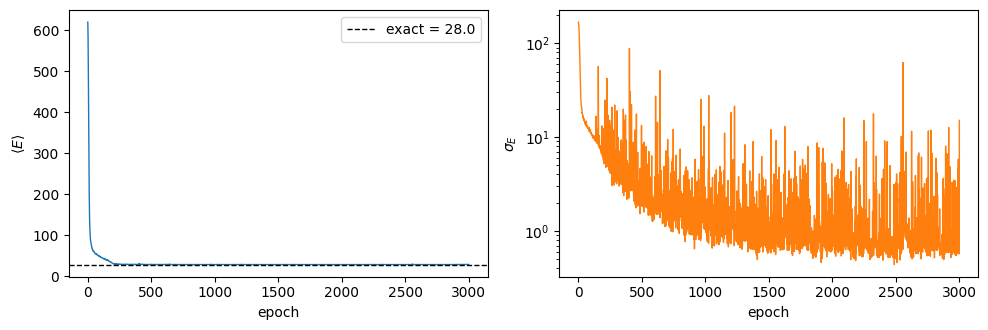

In [ ]:
energy = result.history.get("energy")
std = result.history.get("std")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(energy, lw=1)
ax[0].axhline(E_exact, color="k", ls="--", lw=1, label=f"exact = {E_exact}")
ax[0].set(xlabel="epoch", ylabel=r"$\langle E \rangle$")
ax[0].legend()
ax[1].plot(std, lw=1, color="tab:orange")
ax[1].set(xlabel="epoch", ylabel=r"$\sigma_E$", yscale="log")
fig.tight_layout()

print(f"tail energy {np.mean(energy[-100:]):.4f}   exact {E_exact}")